In [1]:
import sys
import torch
import torchvision
import cv2
import numpy as np

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Using device:", device)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
OpenCV: 4.14.0
GPU available: True
GPU: Tesla T4
Using device: cuda


In [2]:
import torch
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
model = resnet18(weights=weights).to(device)
model.eval()

# Simulate one RGB image: batch, channels, height, width
image = torch.randn(1, 3, 224, 224, device=device)

with torch.no_grad():
    output = model(image)

print("Output shape:", output.shape)
print("Model device:", next(model.parameters()).device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 166MB/s]


Output shape: torch.Size([1, 1000])
Model device: cuda:0


In [3]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.2860,), (0.3530,))
])

full_train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [55000, 5000],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(
    train_dataset, batch_size=128, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset, batch_size=128, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset, batch_size=128, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Device: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 10.5MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 171kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.21MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.2MB/s]

Training images: 55000
Validation images: 5000
Test images: 10000


In [4]:
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = FashionCNN().to(device)

print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Parameters: 421642


In [5]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        # 1. Clear gradients from the previous batch
        optimizer.zero_grad(set_to_none=True)

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update model weights
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += batch_size

    return total_loss / total, correct / total

In [6]:
num_epochs = 5
best_val_accuracy = 0.0

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": []
}

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(
        model, train_loader, criterion, optimizer, device
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, criterion, device
    )

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy
        torch.save(model.state_dict(), "best_fashion_cnn.pth")

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_accuracy:.2%} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_accuracy:.2%}"
    )

Epoch 1/5 | Train Loss: 0.5290 | Train Acc: 80.80% | Val Loss: 0.3595 | Val Acc: 86.28%
Epoch 2/5 | Train Loss: 0.3346 | Train Acc: 87.94% | Val Loss: 0.3028 | Val Acc: 88.70%
Epoch 3/5 | Train Loss: 0.2859 | Train Acc: 89.66% | Val Loss: 0.2713 | Val Acc: 90.00%
Epoch 4/5 | Train Loss: 0.2537 | Train Acc: 90.90% | Val Loss: 0.2526 | Val Acc: 90.88%
Epoch 5/5 | Train Loss: 0.2292 | Train Acc: 91.63% | Val Loss: 0.2480 | Val Acc: 90.58%


In [7]:
model.load_state_dict(
    torch.load(
        "best_fashion_cnn.pth",
        map_location=device,
        weights_only=True
    )
)

test_loss, test_accuracy = evaluate(
    model, test_loader, criterion, device
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2%}")

Test Loss: 0.2580
Test Accuracy: 90.37%


In [8]:
if torch.cuda.is_available():
    print(
        "Allocated:",
        round(torch.cuda.memory_allocated() / 1024**2, 2),
        "MiB"
    )

    print(
        "Reserved:",
        round(torch.cuda.memory_reserved() / 1024**2, 2),
        "MiB"
    )

Allocated: 24.27 MiB
Reserved: 162.0 MiB


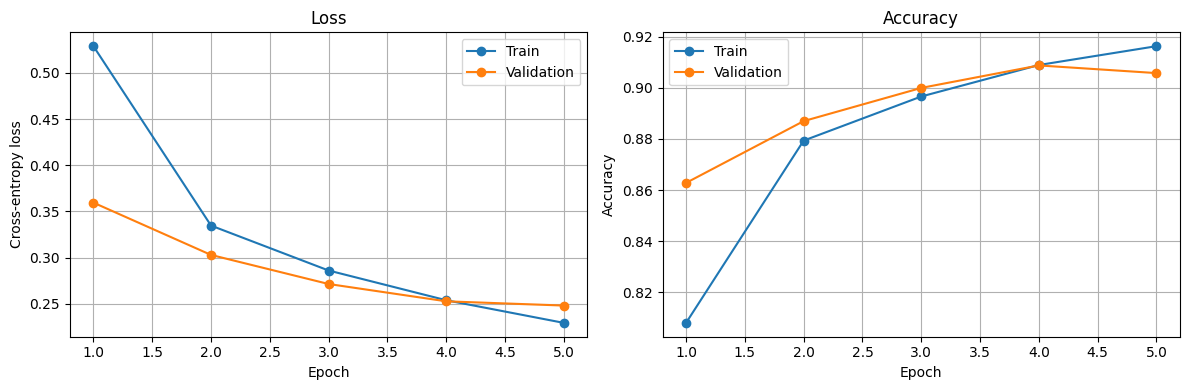

In [9]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history["train_loss"], marker="o", label="Train")
axes[0].plot(epochs, history["val_loss"], marker="o", label="Validation")
axes[0].set_title("Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(epochs, history["train_accuracy"], marker="o", label="Train")
axes[1].plot(epochs, history["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


              precision    recall  f1-score   support

 T-shirt/top      0.825     0.881     0.852      1000
     Trouser      0.992     0.980     0.986      1000
    Pullover      0.797     0.892     0.842      1000
       Dress      0.877     0.932     0.904      1000
        Coat      0.845     0.831     0.838      1000
      Sandal      0.986     0.981     0.983      1000
       Shirt      0.798     0.625     0.701      1000
     Sneaker      0.954     0.967     0.960      1000
         Bag      0.991     0.981     0.986      1000
  Ankle boot      0.970     0.967     0.968      1000

    accuracy                          0.904     10000
   macro avg      0.903     0.904     0.902     10000
weighted avg      0.903     0.904     0.902     10000



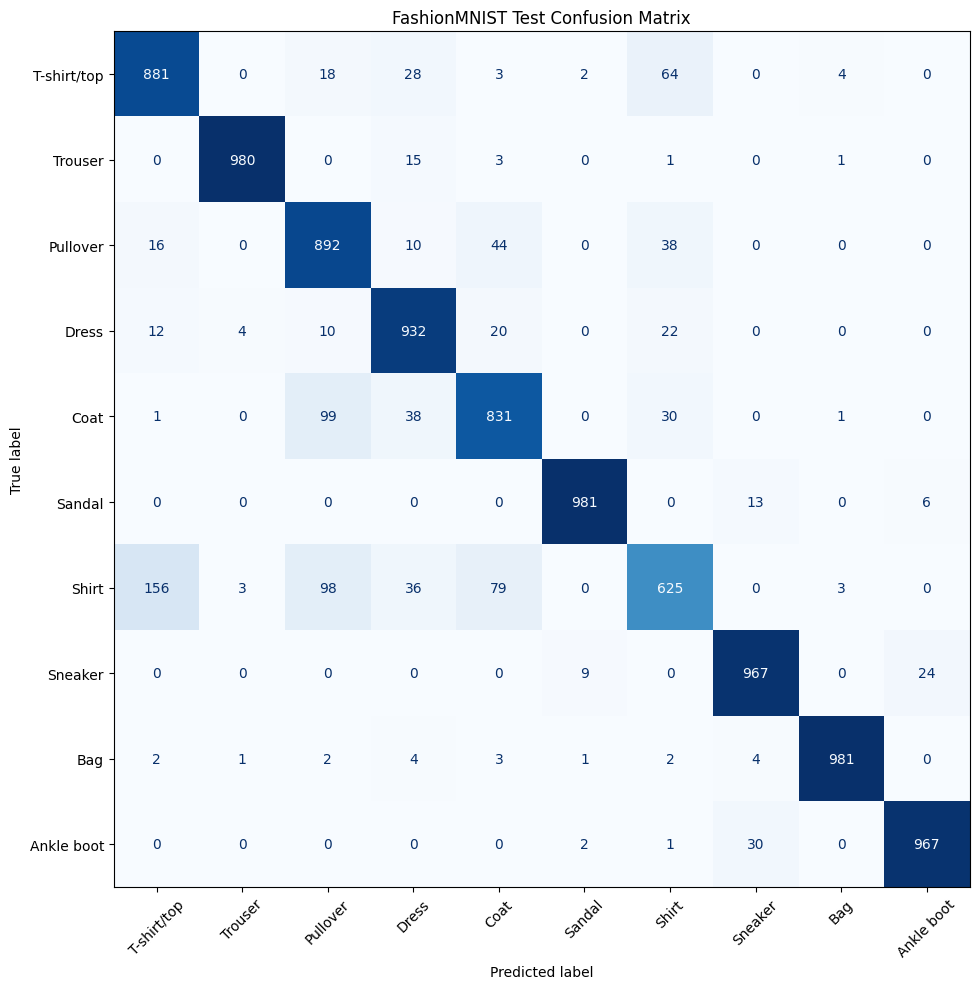

In [10]:
import torch
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        logits = model(images)
        predictions = logits.argmax(dim=1)

        all_predictions.extend(predictions.cpu().tolist())
        all_labels.extend(labels.tolist())

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print(classification_report(
    all_labels,
    all_predictions,
    labels=list(range(10)),
    target_names=class_names,
    digits=3,
    zero_division=0
))

cm = confusion_matrix(
    all_labels, all_predictions, labels=list(range(10))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(10, 10))
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("FashionMNIST Test Confusion Matrix")
plt.tight_layout()
plt.show()

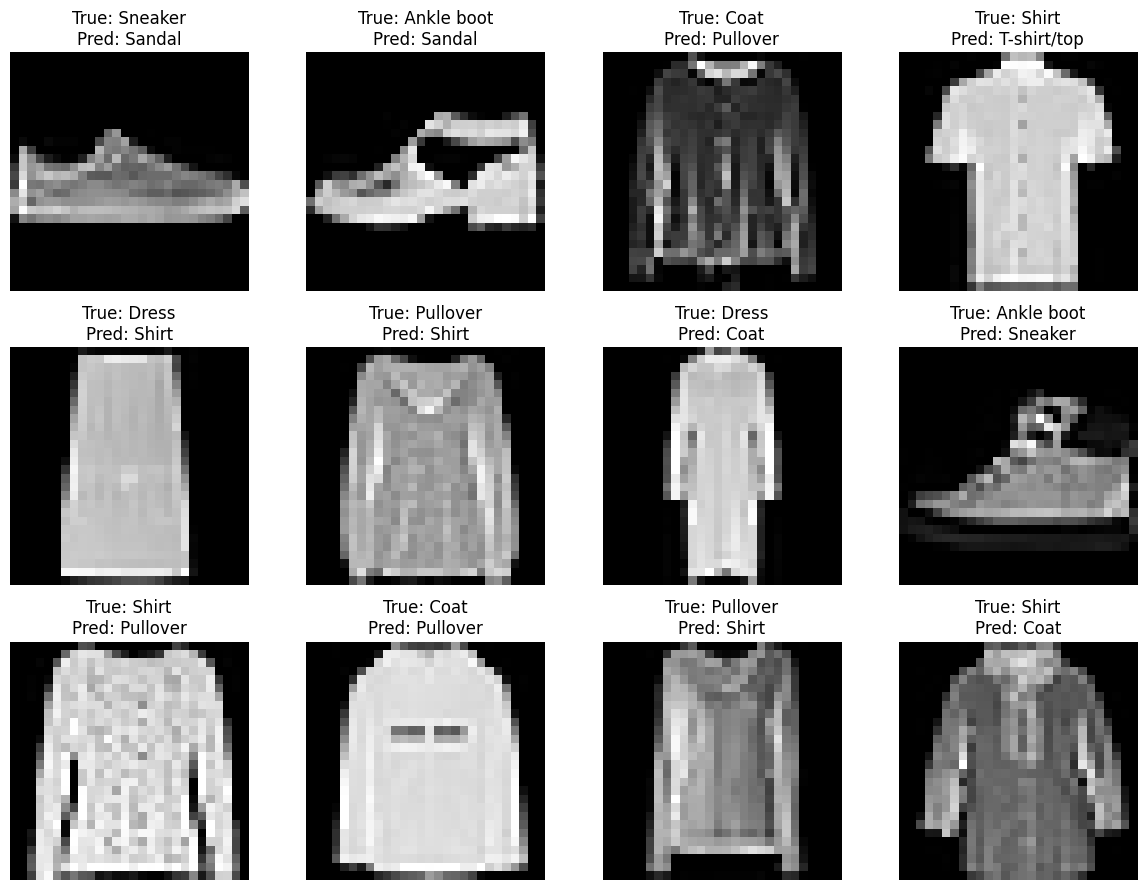

In [11]:
model.eval()
wrong_images = []
wrong_labels = []
wrong_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(device))
        preds = logits.argmax(dim=1).cpu()

        wrong = preds != labels

        for idx in wrong.nonzero(as_tuple=True)[0].tolist():
            wrong_images.append(images[idx].cpu())
            wrong_labels.append(labels[idx].item())
            wrong_predictions.append(preds[idx].item())

            if len(wrong_images) >= 12:
                break

        if len(wrong_images) >= 12:
            break

fig, axes = plt.subplots(3, 4, figsize=(12, 9))

for i, ax in enumerate(axes.flat):
    # Undo normalization for visualization
    image = wrong_images[i].squeeze() * 0.3530 + 0.2860
    image = image.clamp(0, 1)

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {class_names[wrong_labels[i]]}\n"
        f"Pred: {class_names[wrong_predictions[i]]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
checkpoint = {
    "model_state_dict": model.state_dict(),
    "class_names": class_names,
    "mean": [0.2860],
    "std": [0.3530],
}

torch.save(checkpoint, "fashion_cnn_checkpoint.pth")
print("Saved fashion_cnn_checkpoint.pth")

Saved fashion_cnn_checkpoint.pth


In [13]:
checkpoint = torch.load(
    "fashion_cnn_checkpoint.pth",
    map_location=device,
    weights_only=True
)

reloaded_model = FashionCNN().to(device)
reloaded_model.load_state_dict(checkpoint["model_state_dict"])
reloaded_model.eval()

print("Checkpoint loaded successfully.")

Checkpoint loaded successfully.
